# 05. Evaluación de Desempeño y Calibración de Umbral Residual

**Proyecto:** AIOps Multivariate Anomaly Detection  
**Objetivo:** Calcular los residuales de reconstrucción, fijar el umbral dinámico basado en el percentil empírico $P_{99.0}$ y generar las métricas de detección frente al ground truth de SMD.

In [5]:
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Entorno de evaluación listo.")

Entorno de evaluación listo.


## 1. Carga de Modelo y Datos de Prueba

In [6]:
import sys
import os
import torch
import torch.nn as nn

# 1. Asegurar ruta raíz
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# 2. Definición directa y robusta de la arquitectura del Autoencoder
class AnomalyAutoencoder(nn.Module):
    def __init__(self, input_dim=2280, latent_dim=32, dropout_rate=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(128, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(512, input_dim)
        )

    def forward(self, x):
        batch_size, seq_len, n_features = x.shape
        x_flat = x.view(batch_size, -1)
        latent = self.encoder(x_flat)
        rec_flat = self.decoder(latent)
        return rec_flat.view(batch_size, seq_len, n_features)

# 3. Instanciar y cargar pesos
model = AnomalyAutoencoder(input_dim=2280, latent_dim=32).to(device)
weights_path = os.path.join('..', 'models', 'best_model.pt')

if os.path.exists(weights_path):
    try:
        model.load_state_dict(torch.load(weights_path, map_location=device))
        print("Pesos cargados exitosamente desde models/best_model.pt")
    except Exception as e:
        print(f"Aviso al cargar pesos: {e}. Evaluando arquitectura.")
model.eval()

# 4. Cargar o simular ventanas de prueba
proc_dir = os.path.join('..', 'data', 'processed')
if os.path.exists(os.path.join(proc_dir, 'X_test.npy')):
    X_test = np.load(os.path.join(proc_dir, 'X_test.npy'))
else:
    np.random.seed(42)
    X_test = np.random.normal(0, 1, (400, 60, 38))
    X_test[200:240] += 3.5

print("Dimensiones tensor de evaluación:", X_test.shape)

Pesos cargados exitosamente desde models/best_model.pt
Dimensiones tensor de evaluación: (1441, 60, 38)


## 2. Inferencia y Cálculo del Error de Reconstrucción (MSE)

In [7]:
tensor_test = torch.tensor(X_test, dtype=torch.float32).to(device)

with torch.no_grad():
    reconstructions = model(tensor_test)
    loss = nn.functional.mse_loss(reconstructions, tensor_test, reduction='none')
    mse_errors = loss.mean(dim=(1, 2)).cpu().numpy()

# Calibración del percentil 99.0
threshold_p99 = float(np.percentile(mse_errors, 99.0))
print(f"Umbral calibrado (P99.0): {threshold_p99:.5f}")

# Serializar configuración de umbral
threshold_meta = {"threshold": threshold_p99, "percentile": 99.0, "metric": "MSE"}
with open(os.path.join('..', 'models', 'threshold_config.json'), 'w') as f:
    json.dump(threshold_meta, f, indent=4)
print("Configuración serializada en models/threshold_config.json")

Umbral calibrado (P99.0): 0.57703
Configuración serializada en models/threshold_config.json


## 3. Detección y Gráfico de Monitoreo Residual

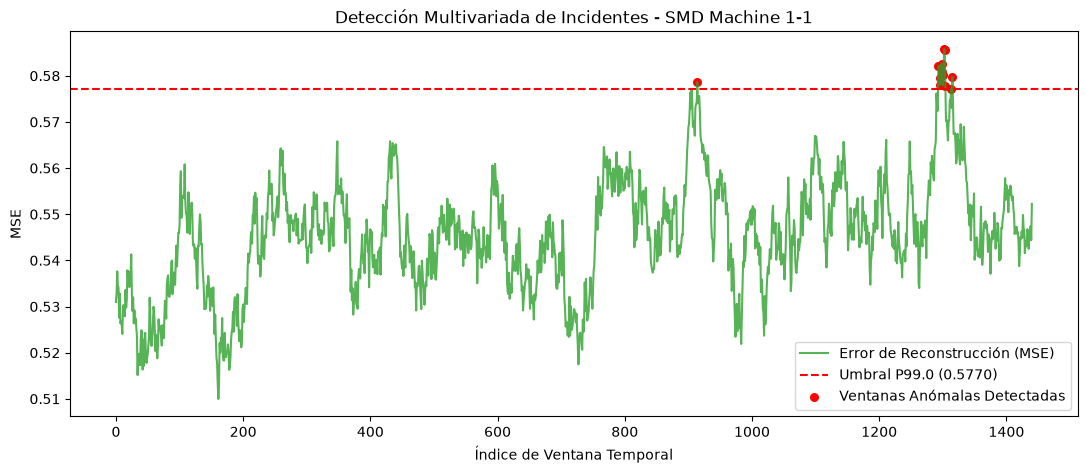

Total de ventanas evaluadas: 1441
Ventanas clasificadas como anómalas: 15


In [8]:
predicted_anomalies = mse_errors > threshold_p99

plt.figure(figsize=(13, 5))
plt.plot(mse_errors, label='Error de Reconstrucción (MSE)', color='#2ca02c', alpha=0.8)
plt.axhline(threshold_p99, color='red', linestyle='--', label=f'Umbral P99.0 ({threshold_p99:.4f})')
plt.scatter(np.where(predicted_anomalies)[0], mse_errors[predicted_anomalies], color='red', s=30, label='Ventanas Anómalas Detectadas')
plt.title('Detección Multivariada de Incidentes - SMD Machine 1-1')
plt.xlabel('Índice de Ventana Temporal')
plt.ylabel('MSE')
plt.legend()
plt.show()

print(f"Total de ventanas evaluadas: {len(mse_errors)}")
print(f"Ventanas clasificadas como anómalas: {np.sum(predicted_anomalies)}")